# Environmental and Vector Analysis Pipeline
## Correlation between climate and vector abundance in Selected Study Area

### 1. Setup and Imports

In [72]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import text
import geopandas as gpd
from shapely import wkt
import contextily as ctx
import warnings
warnings.filterwarnings('ignore')

# Add project root to path
project_root = Path.cwd().parent
sys.path.append(str(project_root))

from database.session import engine
from database.models import Location, VectorObservation, EnvironmentalFactor

# Set plotting style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

### 2. Configuration - Set Analysis Parameters

In [73]:
# ===== CONFIGURATION =====
# Set the study area parameters

# Filter by country (all regions within country)
STUDY_COUNTRY = "Ghana"  # e.g., "Ghana", "Kenya"
STUDY_COUNTRY_CODE = "GH"  # ISO country code (e.g., "GH", "KE")

# Optionally filter by specific region name within the country
# Set to None to include all regions in the country
STUDY_REGION = "Greater Accra"  # e.g., "Greater Accra", "Siaya", or None for all

# Species filter
VECTOR_SPECIES = '%gambiae%'  # SQL LIKE pattern for species

# Date range (optional - set to None for all dates)
START_DATE = None  # e.g., '2024-01-01'
END_DATE = None    # e.g., '2025-12-31'

print(f"Analysis Configuration:")
print(f"- Country: {STUDY_COUNTRY} ({STUDY_COUNTRY_CODE})")
print(f"- Region: {STUDY_REGION if STUDY_REGION else 'All regions'}")
print(f"- Species: {VECTOR_SPECIES}")
print(f"- Date range: {START_DATE if START_DATE else 'All dates'} to {END_DATE if END_DATE else 'All dates'}")

Analysis Configuration:
- Country: Ghana (GH)
- Region: Greater Accra
- Species: %gambiae%
- Date range: All dates to All dates


### 3. Data Loading Functions

In [74]:
def load_study_locations(country_name, country_code, region_name=None):
    """Load location data for a specific country and optional region."""
    
    query = """
    SELECT 
        location_code,
        name,
        admin_level,
        geometry_wkt,
        centroid_lat,
        centroid_lon,
        country_name,
        country_code
    FROM location
    WHERE country_name = :country_name 
       OR country_code = :country_code
    """
    
    params = {'country_name': country_name, 'country_code': country_code}
    
    if region_name:
        query += " AND name = :region_name"
        params['region_name'] = region_name
    
    df_locations = pd.read_sql(text(query), engine, params=params)
    
    print(f"Found {len(df_locations)} locations in {country_name}")
    
    # Convert to GeoDataFrame for locations with geometry
    gdf_locations = None
    if len(df_locations) > 0 and 'geometry_wkt' in df_locations.columns:
        # Filter out rows without geometry
        df_with_geom = df_locations[df_locations['geometry_wkt'].notna()].copy()
        if len(df_with_geom) > 0:
            df_with_geom['geometry'] = df_with_geom['geometry_wkt'].apply(wkt.loads)
            gdf_locations = gpd.GeoDataFrame(df_with_geom, crs='EPSG:4326')
    
    return df_locations, gdf_locations


def load_vector_data(location_codes, species_filter='%gambiae%', start_date=None, end_date=None):
    """Load vector observation data for specified location codes."""
    
    if not location_codes:
        print("No location codes provided")
        return pd.DataFrame(), None
    
    # Create placeholders for SQL IN clause
    placeholders = ','.join([f':code_{i}' for i in range(len(location_codes))])
    params = {f'code_{i}': code for i, code in enumerate(location_codes)}
    params['species'] = species_filter
    
    query = f"""
    SELECT 
        v.date_id,
        v.location_code,
        v.vector_species,
        v.count,
        l.centroid_lat AS lat,
        l.centroid_lon AS lon,
        l.geometry_wkt AS geom_wkt,
        l.name AS location_name,
        l.admin_level,
        l.country_name,
        l.country_code
    FROM vector_observation v
    JOIN location l ON v.location_code = l.location_code
    WHERE v.vector_species LIKE :species
      AND v.location_code IN ({placeholders})
    """
    
    if start_date:
        query += " AND v.date_id >= :start_date"
        params['start_date'] = start_date
    
    if end_date:
        query += " AND v.date_id <= :end_date"
        params['end_date'] = end_date
    
    query += " ORDER BY v.date_id"
    
    df_vec = pd.read_sql(text(query), engine, params=params)
    print(f"Total vector observations: {len(df_vec)}")
    
    # Convert to GeoDataFrame if we have coordinates
    gdf_points = None
    if len(df_vec) > 0:
        df_with_coords = df_vec[df_vec['lat'].notna() & df_vec['lon'].notna()].copy()
        if len(df_with_coords) > 0:
            gdf_points = gpd.GeoDataFrame(
                df_with_coords,
                geometry=gpd.points_from_xy(df_with_coords['lon'], df_with_coords['lat']),
                crs='EPSG:4326'
            )
    
    return df_vec, gdf_points


def load_environmental_data(location_codes, start_date=None, end_date=None):
    """Load environmental data for specified location codes."""
    
    if not location_codes:
        print("No location codes provided")
        return pd.DataFrame()
    
    # Create placeholders for SQL IN clause
    placeholders = ','.join([f':code_{i}' for i in range(len(location_codes))])
    params = {f'code_{i}': code for i, code in enumerate(location_codes)}
    
    query = f"""
    SELECT 
        e.date_id,
        e.location_code,
        e.temperature_mean,
        e.rainfall_total,
        l.name AS location_name,
        l.country_name,
        l.country_code
    FROM environmental_factor e
    JOIN location l ON e.location_code = l.location_code
    WHERE e.location_code IN ({placeholders})
    """
    
    if start_date:
        query += " AND e.date_id >= :start_date"
        params['start_date'] = start_date
    
    if end_date:
        query += " AND e.date_id <= :end_date"
        params['end_date'] = end_date
    
    query += " ORDER BY e.date_id"
    
    df_env = pd.read_sql(text(query), engine, params=params)
    df_env['date'] = pd.to_datetime(df_env['date_id'])
    print(f"Environmental records: {len(df_env)} days")
    
    return df_env

### 4. Load Data

In [75]:
# Load data based on configuration
df_locations, gdf_locations = load_study_locations(STUDY_COUNTRY, STUDY_COUNTRY_CODE, STUDY_REGION)

if len(df_locations) == 0:
    print(f"No locations found for {STUDY_COUNTRY}. Please check country name/code.")
    # Show available countries as a hint
    countries_df = pd.read_sql("SELECT DISTINCT country_name, country_code FROM location WHERE country_name IS NOT NULL", engine)
    print("\nAvailable countries in database:")
    print(countries_df.to_string(index=False))
else:
    location_codes = df_locations['location_code'].tolist()
    
    # Load vector data
    df_vec, gdf_points = load_vector_data(location_codes, VECTOR_SPECIES, START_DATE, END_DATE)
    
    # Load environmental data
    df_env = load_environmental_data(location_codes, START_DATE, END_DATE)

    # Display summary
    print(f"\nData Summary:")
    print(f"- Locations: {len(df_locations)}")
    print(f"- Vector observations: {len(df_vec)}")
    print(f"- Environmental records: {len(df_env)}")

Found 41 locations in Ghana
Total vector observations: 40
Environmental records: 1465 days

Data Summary:
- Locations: 41
- Vector observations: 40
- Environmental records: 1465


### 5. Spatial Filtering to Region Boundary

In [76]:
def get_region_boundary(region_name, country_name=None):
    """Get the boundary polygon for a specific region."""
    query = """
    SELECT geometry_wkt, name, admin_level
    FROM location
    WHERE name = :region_name
    """
    params = {'region_name': region_name}
    
    if country_name:
        query += " AND (country_name = :country_name OR country_code = :country_code)"
        params['country_name'] = country_name
        params['country_code'] = STUDY_COUNTRY_CODE
    
    result = pd.read_sql(text(query), engine, params=params)
    
    if len(result) == 0:
        print(f"No boundary found for region: {region_name}")
        return None
    
    boundary = wkt.loads(result.iloc[0]['geometry_wkt'])
    gdf_boundary = gpd.GeoDataFrame({'geometry': [boundary]}, crs='EPSG:4326')
    
    print(f"Found boundary for {region_name} (admin_level: {result.iloc[0]['admin_level']})")
    return gdf_boundary


# Apply spatial filter if region boundary is available
gdf_filtered_points = gdf_points.copy() if gdf_points is not None else None

if STUDY_REGION and gdf_points is not None:
    region_boundary = get_region_boundary(STUDY_REGION, STUDY_COUNTRY)
    if region_boundary is not None:
        gdf_filtered_points = gdf_points[gdf_points.within(region_boundary.unary_union)]
        print(f"Points within {STUDY_REGION}: {len(gdf_filtered_points)} (out of {len(gdf_points)} total)")
    else:
        print(f"No boundary found for {STUDY_REGION}. Using all points in {STUDY_COUNTRY}.")
        gdf_filtered_points = gdf_points
else:
    if gdf_points is not None:
        print(f"Using all {len(gdf_points)} points in {STUDY_COUNTRY}")
        gdf_filtered_points = gdf_points

Found boundary for Greater Accra (admin_level: region)
Points within Greater Accra: 36 (out of 40 total)


### 6. Diagnostic: Check Location Code Compatibility

In [77]:
print("=== LOCATION CODE DIAGNOSTIC ===\n")

# Check vector data locations
vector_locs = set(df_vec['location_code'].unique()) if df_vec is not None else set()
print(f"Vector observation location codes ({len(vector_locs)} unique):")
print(sorted(vector_locs)[:10] if len(vector_locs) > 10 else sorted(vector_locs))

# Check environmental data locations
env_locs = set(df_env['location_code'].unique()) if df_env is not None else set()
print(f"\nEnvironmental data location codes ({len(env_locs)} unique):")
print(sorted(env_locs))

# Check for matching location codes
common_locs = vector_locs.intersection(env_locs)
print(f"\nCommon location codes: {common_locs}")
print(f"Number of common locations: {len(common_locs)}")

if len(common_locs) == 0:
    print("\n⚠️ No common location codes found! Environmental and vector data cannot be merged directly.")
    print("This typically happens because vector data is stored at point locations,")
    print("while environmental data is stored at region/county level.")
    print("\nWe'll need to aggregate vector data to the region level.")

=== LOCATION CODE DIAGNOSTIC ===

Vector observation location codes (5 unique):
['point_5_7810_0_5860', 'point_5_8830_0_1170', 'point_6_5833_0_3333', 'point_6_9167_0_2500', 'point_6_9500_0_2333']

Environmental data location codes (1 unique):
['greater_accra']

Common location codes: set()
Number of common locations: 0

⚠️ No common location codes found! Environmental and vector data cannot be merged directly.
This typically happens because vector data is stored at point locations,
while environmental data is stored at region/county level.

We'll need to aggregate vector data to the region level.


### 7. Create Location Hierarchy Mapping (Fixed SQL Syntax)

In [78]:
def create_location_mapping(point_codes):
    """Create a mapping from point location codes to their parent region codes.
       Fixed for SQLite syntax."""
    
    if not point_codes or len(point_codes) == 0:
        print("No point codes provided")
        return {}
    
    # SQLite doesn't support tuple parameters with IN clause well
    # Create a string with placeholders
    placeholders = ','.join(['?' for _ in point_codes])
    
    query = f"""
    SELECT 
        location_code as point_code,
        parent_location_code as region_code
    FROM location
    WHERE location_code IN ({placeholders})
    """
    
    # Use pandas to get the mapping
    mapping_df = pd.read_sql(query, engine, params=list(point_codes))
    
    # Convert to dictionary
    location_mapping = dict(zip(mapping_df['point_code'], mapping_df['region_code']))
    
    print(f"Created mapping for {len(location_mapping)} point locations")
    return location_mapping


# Get all point location codes
if gdf_filtered_points is not None:
    point_codes = gdf_filtered_points['location_code'].unique()
    location_mapping = create_location_mapping(point_codes)
    
    # Identify which region codes are in environmental data
    env_region_codes = set(df_env['location_code'].unique()) if df_env is not None else set()
    
    # Find which mapped regions have environmental data
    mapped_regions = set(location_mapping.values()) if location_mapping else set()
    usable_regions = mapped_regions.intersection(env_region_codes)
    
    print(f"Mapped regions with environmental data: {usable_regions}")
    
    if len(usable_regions) == 0:
        print("⚠️ No mapped regions have corresponding environmental data.")
        print("Will attempt to identify the region code from location names.")

DatabaseError: Execution failed on sql '
    SELECT 
        location_code as point_code,
        parent_location_code as region_code
    FROM location
    WHERE location_code IN (?,?)
    ': List argument must consist only of tuples or dictionaries

### 8. Identify Region Code for Study Area

In [79]:
# Try to identify the correct region code for the study area
def find_region_code(region_name, country_code):
    """Find the location code for a region by name."""
    query = """
    SELECT location_code, name
    FROM location
    WHERE name = :region_name AND country_code = :country_code
    """
    result = pd.read_sql(text(query), engine, params={'region_name': region_name, 'country_code': country_code})
    
    if len(result) > 0:
        return result.iloc[0]['location_code']
    return None

region_code = find_region_code(STUDY_REGION, STUDY_COUNTRY_CODE)
if region_code:
    print(f"Found region code: {region_code}")
else:
    print(f"Could not find region code for {STUDY_REGION}")
    # Try lowercase version with underscores
    region_code = STUDY_REGION.lower().replace(' ', '_')
    print(f"Using guessed region code: {region_code}")

Found region code: greater_accra


### 9. Aggregate Vector Data to Region Level

In [80]:
def aggregate_to_region_monthly(gdf_points, region_code):
    """
    Aggregate all vector points in the region to monthly totals.
    This sums counts across all sites within the region for each month.
    """
    
    if gdf_points is None or len(gdf_points) == 0:
        print("No vector points to aggregate")
        return pd.DataFrame()
    
    # Aggregate all points in the region by month
    df_vec_monthly = gdf_points.groupby('date_id')['count'].agg(['sum', 'mean', 'std', 'count']).reset_index()
    df_vec_monthly.columns = ['date_id', 'total_count', 'mean_count', 'std_count', 'n_observations']
    df_vec_monthly['date'] = pd.to_datetime(df_vec_monthly['date_id'])
    df_vec_monthly['location_code'] = region_code
    
    print(f"Monthly vector observations: {len(df_vec_monthly)} months")
    print("Vector date range:", df_vec_monthly['date_id'].min(), "to", df_vec_monthly['date_id'].max())
    
    return df_vec_monthly


# Aggregate vector data to region level
if gdf_filtered_points is not None and len(gdf_filtered_points) > 0:
    df_vec_region = aggregate_to_region_monthly(gdf_filtered_points, region_code)
else:
    print("No vector data to aggregate")
    df_vec_region = pd.DataFrame()

Monthly vector observations: 7 months
Vector date range: 2017-02-01 to 2018-06-01


### 10. Aggregate Environmental Data to Monthly

In [81]:
def aggregate_environmental_monthly(df_env, region_code):
    """Aggregate daily environmental data to monthly means for a specific region."""
    
    if df_env is None or len(df_env) == 0:
        print("No environmental data to aggregate")
        return pd.DataFrame()
    
    # Filter for the region
    df_env_region = df_env[df_env['location_code'] == region_code].copy()
    
    if len(df_env_region) == 0:
        print(f"No environmental data found for region code: {region_code}")
        print(f"Available environmental location codes: {df_env['location_code'].unique()}")
        return pd.DataFrame()
    
    # Environmental monthly aggregation
    numeric_cols = ['temperature_mean', 'rainfall_total']
    df_env_indexed = df_env_region.set_index('date').copy()
    
    df_env_monthly = df_env_indexed[numeric_cols].resample('ME').agg(['mean', 'std', 'min', 'max'])
    df_env_monthly.columns = ['_'.join(col).strip() for col in df_env_monthly.columns.values]
    df_env_monthly = df_env_monthly.reset_index()
    df_env_monthly['date_id'] = df_env_monthly['date'].dt.strftime('%Y-%m-01')
    df_env_monthly['location_code'] = region_code
    
    print(f"Monthly environmental records: {len(df_env_monthly)} months")
    print("Environmental date range:", df_env_monthly['date_id'].min(), "to", df_env_monthly['date_id'].max())
    
    return df_env_monthly


# Aggregate environmental data
df_env_monthly = aggregate_environmental_monthly(df_env, region_code)

Monthly environmental records: 133 months
Environmental date range: 2014-12-01 to 2025-12-01


### 11. Merge Vector and Environmental Data

In [82]:
def merge_datasets(df_vec, df_env):
    """Merge vector and environmental datasets on date."""
    
    if df_vec.empty or df_env.empty:
        print("Cannot merge: one or both datasets are empty")
        return pd.DataFrame()
    
    # Merge on date_id
    df_merged = pd.merge(
        df_vec,
        df_env,
        on='date_id',
        how='inner'
    )
    
    print(f"Overlapping months: {len(df_merged)}")
    
    if len(df_merged) > 0:
        # Ensure date column exists (from vector data)
        if 'date_x' in df_merged.columns:
            df_merged['date'] = df_merged['date_x']
        elif 'date' not in df_merged.columns:
            df_merged['date'] = pd.to_datetime(df_merged['date_id'])
        
        print(f"Date range: {df_merged['date_id'].min()} to {df_merged['date_id'].max()}")
    
    return df_merged


# Merge the datasets
df_merged = merge_datasets(df_vec_region, df_env_monthly)

if df_merged.empty:
    print("⚠️ No overlapping months found. Cannot proceed with analysis.")

Overlapping months: 7
Date range: 2017-02-01 to 2018-06-01


### 12. Time Series Visualization (Fixed Date Column Issue)

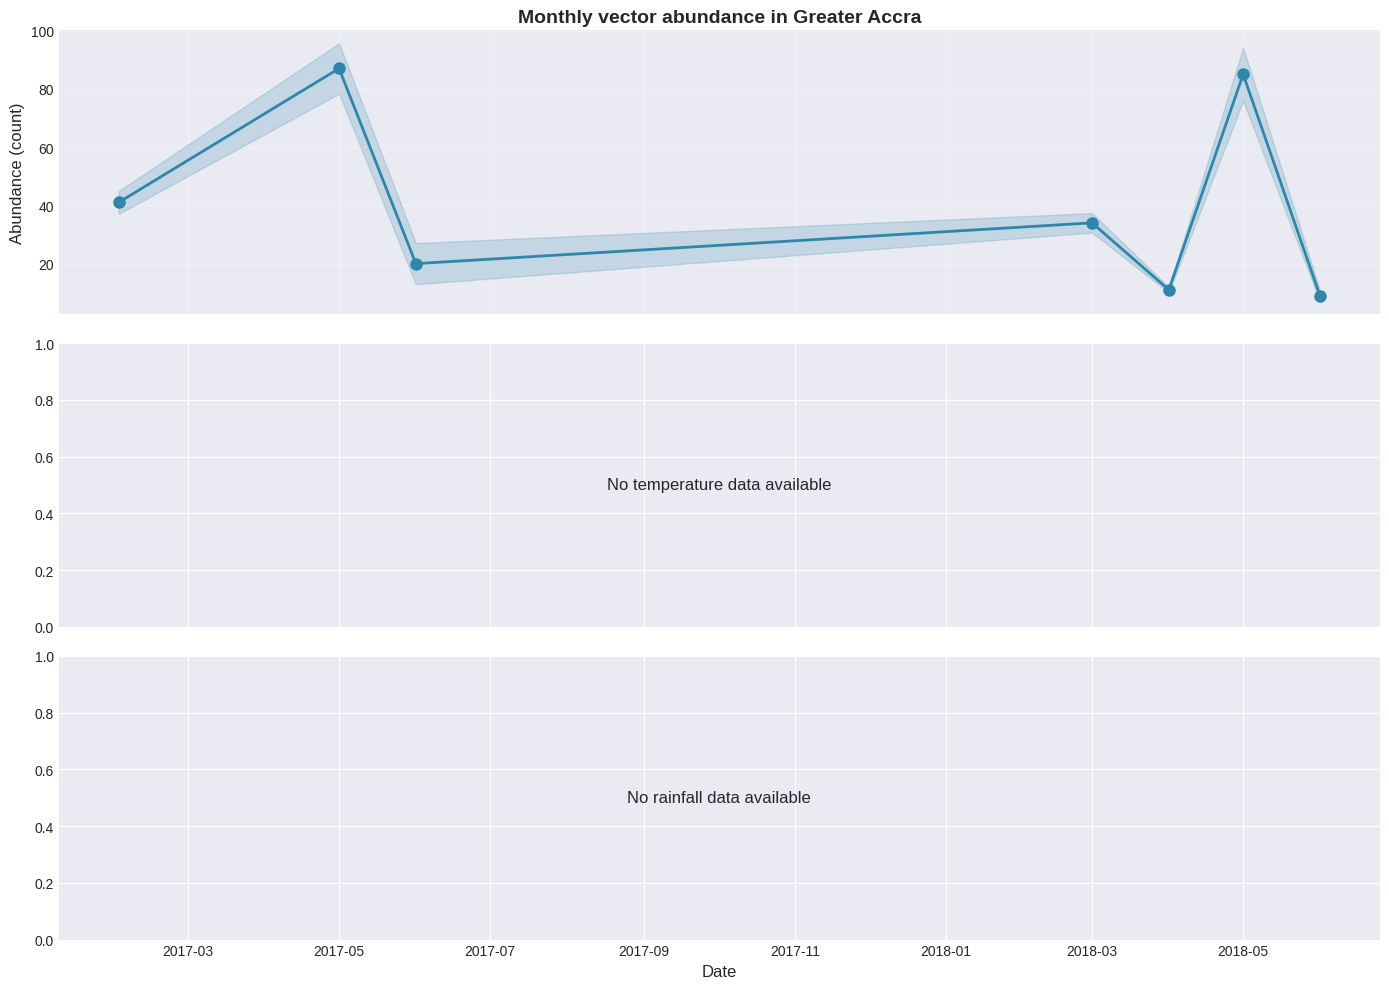

In [83]:
def plot_time_series(df_merged, region_name):
    """Create comprehensive time series visualization."""
    
    if df_merged.empty:
        print("No data to plot")
        return
    
    # Ensure date column exists and is datetime
    if 'date' not in df_merged.columns:
        df_merged['date'] = pd.to_datetime(df_merged['date_id'])
    
    fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
    
    region_title = region_name if region_name else STUDY_COUNTRY
    
    # Abundance
    axes[0].plot(df_merged['date'], df_merged['total_count'], 
                 marker='o', linestyle='-', linewidth=2, markersize=8, color='#2E86AB')
    if 'std_count' in df_merged.columns and not df_merged['std_count'].isna().all():
        axes[0].fill_between(df_merged['date'], 
                              df_merged['total_count'] - df_merged['std_count'],
                              df_merged['total_count'] + df_merged['std_count'],
                              alpha=0.2, color='#2E86AB')
    axes[0].set_ylabel('Abundance (count)', fontsize=12)
    axes[0].set_title(f'Monthly vector abundance in {region_title}', fontsize=14, fontweight='bold')
    axes[0].grid(True, alpha=0.3)
    
    # Temperature
    if 'temperature_mean_mean' in df_merged.columns and not df_merged['temperature_mean_mean'].isna().all():
        axes[1].plot(df_merged['date'], df_merged['temperature_mean_mean'], 
                     marker='s', linestyle='-', linewidth=2, markersize=8, color='#A23B72')
        if 'temperature_mean_std' in df_merged.columns and not df_merged['temperature_mean_std'].isna().all():
            axes[1].fill_between(df_merged['date'],
                                  df_merged['temperature_mean_mean'] - df_merged['temperature_mean_std'],
                                  df_merged['temperature_mean_mean'] + df_merged['temperature_mean_std'],
                                  alpha=0.2, color='#A23B72')
        axes[1].set_ylabel('Temperature (°C)', fontsize=12)
        axes[1].set_title('Monthly mean temperature', fontsize=14, fontweight='bold')
        axes[1].grid(True, alpha=0.3)
    else:
        axes[1].text(0.5, 0.5, 'No temperature data available', 
                    ha='center', va='center', transform=axes[1].transAxes, fontsize=12)
    
    # Rainfall
    if 'rainfall_total_mean' in df_merged.columns and not df_merged['rainfall_total_mean'].isna().all():
        axes[2].bar(df_merged['date'], df_merged['rainfall_total_mean'], 
                    width=20, color='#F18F01', alpha=0.7, label='Mean rainfall')
        if 'rainfall_total_std' in df_merged.columns and not df_merged['rainfall_total_std'].isna().all():
            axes[2].errorbar(df_merged['date'], df_merged['rainfall_total_mean'],
                             yerr=df_merged['rainfall_total_std'],
                             fmt='none', color='black', capsize=5)
        axes[2].set_ylabel('Rainfall (mm)', fontsize=12)
        axes[2].set_title('Monthly total rainfall', fontsize=14, fontweight='bold')
        axes[2].grid(True, alpha=0.3)
    else:
        axes[2].text(0.5, 0.5, 'No rainfall data available', 
                    ha='center', va='center', transform=axes[2].transAxes, fontsize=12)
    
    plt.xlabel('Date', fontsize=12)
    plt.tight_layout()
    plt.show()


if not df_merged.empty:
    plot_time_series(df_merged, STUDY_REGION)
else:
    print("No data available for time series plot")

### 13. Correlation Analysis (Fixed NaN Handling)

In [84]:
def analyze_correlations(df_merged):
    """Compute and visualize correlations with error handling."""
    
    if df_merged.empty or len(df_merged) < 3:
        print("Insufficient data for correlation analysis (need at least 3 months)")
        return None
    
    # Check which columns are available and have data
    available_cols = ['total_count']
    has_temp = False
    has_rain = False
    
    if 'temperature_mean_mean' in df_merged.columns:
        if not df_merged['temperature_mean_mean'].isna().all():
            available_cols.append('temperature_mean_mean')
            has_temp = True
        else:
            print("Note: temperature_mean_mean column exists but all values are NaN")
    
    if 'rainfall_total_mean' in df_merged.columns:
        if not df_merged['rainfall_total_mean'].isna().all():
            available_cols.append('rainfall_total_mean')
            has_rain = True
        else:
            print("Note: rainfall_total_mean column exists but all values are NaN")
    
    if len(available_cols) < 2:
        print("Not enough valid variables for correlation analysis")
        return None
    
    # Basic correlations (only on columns with data)
    corr_matrix = df_merged[available_cols].corr()
    
    print("\n=== CORRELATION ANALYSIS ===")
    print(f"Based on {len(df_merged)} months of overlapping data")
    print("\nCorrelation Matrix:")
    print(corr_matrix.round(3))
    
    # Create plots
    plot_count = 1 + (1 if has_temp else 0) + (1 if has_rain else 0)
    fig, axes = plt.subplots(1, plot_count, figsize=(5*plot_count, 5))
    
    if plot_count == 1:
        axes = [axes]
    
    plot_idx = 0
    
    # Correlation matrix heatmap
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0,
                square=True, ax=axes[plot_idx], cbar_kws={"shrink": 0.8},
                annot_kws={"size": 12})
    axes[plot_idx].set_title('Correlation Matrix', fontsize=12, fontweight='bold')
    plot_idx += 1
    
    # Temperature scatter
    if has_temp:
        axes[plot_idx].scatter(df_merged['temperature_mean_mean'], df_merged['total_count'], 
                               s=100, alpha=0.7, color='#A23B72', edgecolors='black')
        axes[plot_idx].set_xlabel('Temperature (°C)', fontsize=11)
        axes[plot_idx].set_ylabel('Abundance', fontsize=11)
        r_val = corr_matrix.loc['total_count', 'temperature_mean_mean']
        axes[plot_idx].set_title(f'Temp vs Abundance\nr = {r_val:.3f}', 
                                  fontsize=12, fontweight='bold')
        
        # Add trend line (with error handling)
        try:
            if len(df_merged) > 2:
                z = np.polyfit(df_merged['temperature_mean_mean'].dropna(), 
                               df_merged['total_count'].loc[df_merged['temperature_mean_mean'].notna()], 1)
                p = np.poly1d(z)
                x_range = np.linspace(df_merged['temperature_mean_mean'].min(), 
                                       df_merged['temperature_mean_mean'].max(), 50)
                axes[plot_idx].plot(x_range, p(x_range), 
                                    '--', color='gray', alpha=0.8, linewidth=2)
        except (np.linalg.LinAlgError, ValueError, TypeError) as e:
            print(f"  Could not add trend line for temperature: {e}")
        
        plot_idx += 1
    
    # Rainfall scatter
    if has_rain:
        axes[plot_idx].scatter(df_merged['rainfall_total_mean'], df_merged['total_count'],
                               s=100, alpha=0.7, color='#F18F01', edgecolors='black')
        axes[plot_idx].set_xlabel('Rainfall (mm)', fontsize=11)
        axes[plot_idx].set_ylabel('Abundance', fontsize=11)
        r_val = corr_matrix.loc['total_count', 'rainfall_total_mean']
        axes[plot_idx].set_title(f'Rainfall vs Abundance\nr = {r_val:.3f}',
                                  fontsize=12, fontweight='bold')
        
        # Add trend line
        try:
            if len(df_merged) > 2:
                z = np.polyfit(df_merged['rainfall_total_mean'].dropna(), 
                               df_merged['total_count'].loc[df_merged['rainfall_total_mean'].notna()], 1)
                p = np.poly1d(z)
                x_range = np.linspace(df_merged['rainfall_total_mean'].min(), 
                                       df_merged['rainfall_total_mean'].max(), 50)
                axes[plot_idx].plot(x_range, p(x_range),
                                    '--', color='gray', alpha=0.8, linewidth=2)
        except (np.linalg.LinAlgError, ValueError, TypeError) as e:
            print(f"  Could not add trend line for rainfall: {e}")
    
    plt.tight_layout()
    plt.show()
    
    return corr_matrix


if not df_merged.empty:
    corr_matrix = analyze_correlations(df_merged)
else:
    print("Cannot perform correlation analysis: no merged data")

Note: temperature_mean_mean column exists but all values are NaN
Note: rainfall_total_mean column exists but all values are NaN
Not enough valid variables for correlation analysis


### 14. Lagged Correlation Analysis (Fixed NaN Handling)

In [85]:
def analyze_lagged_correlations(df_merged, max_lag=3):
    """Analyze lagged correlations between climate variables and abundance."""
    
    if df_merged.empty or len(df_merged) < max_lag + 1:
        print(f"Insufficient data for lagged correlation analysis (need at least {max_lag + 1} months)")
        return {}
    
    # Determine which climate variables are available and have data
    climate_vars = []
    if 'temperature_mean_mean' in df_merged.columns:
        if not df_merged['temperature_mean_mean'].isna().all():
            climate_vars.append(('temperature_mean_mean', 'Temperature', '#A23B72'))
    if 'rainfall_total_mean' in df_merged.columns:
        if not df_merged['rainfall_total_mean'].isna().all():
            climate_vars.append(('rainfall_total_mean', 'Rainfall', '#F18F01'))
    
    if not climate_vars:
        print("No climate variables with valid data available for lagged analysis")
        return {}
    
    n_rows = len(climate_vars)
    fig, axes = plt.subplots(n_rows, max_lag, figsize=(15, 5 * n_rows))
    
    # Handle single row case
    if n_rows == 1:
        axes = axes.reshape(1, -1)
    
    lags = range(1, max_lag + 1)
    lag_correlations = {}
    
    print("\n=== LAGGED CORRELATION ANALYSIS ===")
    
    for row_idx, (var_name, var_label, color) in enumerate(climate_vars):
        var_corrs = []
        print(f"\n{var_label}:")
        
        for i, lag in enumerate(lags):
            # Create lagged variable
            df_lag = df_merged[[var_name, 'total_count']].copy()
            df_lag[f'{var_name}_lag'] = df_lag[var_name].shift(lag)
            df_clean = df_lag.dropna()
            
            if len(df_clean) > 1:
                try:
                    corr = df_clean[[f'{var_name}_lag', 'total_count']].corr().iloc[0, 1]
                    if not np.isnan(corr):
                        var_corrs.append(corr)
                        print(f"  Lag {lag}: r = {corr:.3f} (n={len(df_clean)})")
                        
                        axes[row_idx, i].scatter(df_clean[f'{var_name}_lag'], df_clean['total_count'],
                                                 alpha=0.7, s=80, color=color, edgecolors='black')
                        axes[row_idx, i].set_xlabel(f'{var_label} (lag {lag} mo)', fontsize=10)
                        axes[row_idx, i].set_ylabel('Abundance', fontsize=10)
                        axes[row_idx, i].set_title(f'r = {corr:.3f}\nn={len(df_clean)}', 
                                                   fontsize=11, fontweight='bold')
                        axes[row_idx, i].grid(True, alpha=0.3)
                        
                        # Add trend line if enough points
                        if len(df_clean) > 2:
                            try:
                                z = np.polyfit(df_clean[f'{var_name}_lag'], df_clean['total_count'], 1)
                                p = np.poly1d(z)
                                x_range = np.linspace(df_clean[f'{var_name}_lag'].min(), 
                                                       df_clean[f'{var_name}_lag'].max(), 50)
                                axes[row_idx, i].plot(x_range, p(x_range),
                                                    '--', color='gray', alpha=0.5)
                            except:
                                pass
                    else:
                        axes[row_idx, i].text(0.5, 0.5, 'NaN correlation', 
                                              transform=axes[row_idx, i].transAxes,
                                              ha='center', va='center', fontsize=10)
                except Exception as e:
                    axes[row_idx, i].text(0.5, 0.5, 'Error', 
                                          transform=axes[row_idx, i].transAxes,
                                          ha='center', va='center', fontsize=10)
            else:
                axes[row_idx, i].text(0.5, 0.5, 'Insufficient\ndata', 
                                      transform=axes[row_idx, i].transAxes,
                                      ha='center', va='center', fontsize=10)
        
        lag_correlations[var_label.lower()] = var_corrs
    
    # Set row labels
    for row_idx, (_, var_label, _) in enumerate(climate_vars):
        axes[row_idx, 0].set_ylabel(f'Abundance\n({var_label} lag)', fontsize=11)
    
    plt.suptitle('Lagged Correlation Analysis', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()
    
    return lag_correlations


if not df_merged.empty:
    lag_correlations = analyze_lagged_correlations(df_merged)
else:
    print("Cannot perform lagged correlation analysis: no merged data")

No climate variables with valid data available for lagged analysis


### 15. Improved Spatial Distribution Map

Found boundary for Greater Accra (admin_level: region)


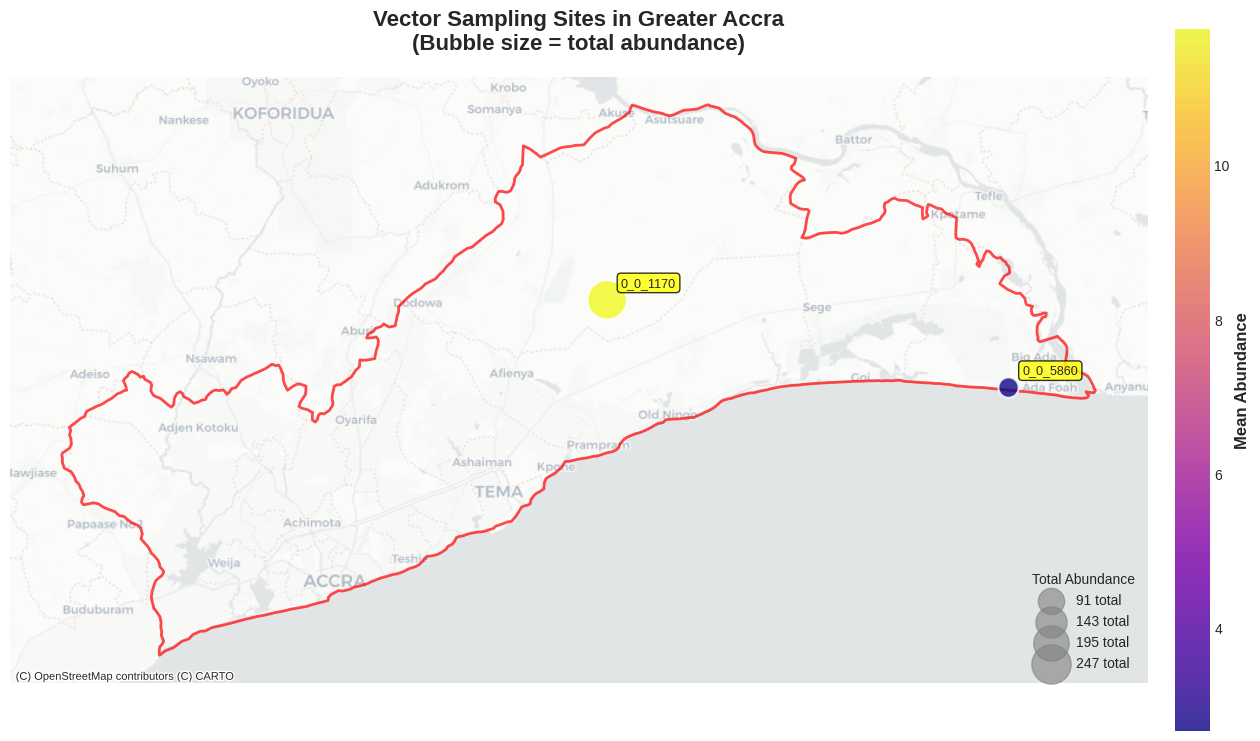

In [86]:
def create_improved_sampling_map(gdf_points, region_name, region_boundary=None):
    """Create an improved map of sampling sites with better visualization."""
    
    if gdf_points is None or len(gdf_points) == 0:
        print("No points to map")
        return None
    
    # Aggregate by site
    df_sites = gdf_points.groupby(['location_code', 'lat', 'lon'], as_index=False)['count'].agg(['sum', 'mean', 'count'])
    df_sites.columns = ['location_code', 'lat', 'lon', 'total_abundance', 'mean_abundance', 'n_observations']
    
    # Filter out sites with very low abundance if needed
    df_sites = df_sites[df_sites['total_abundance'] > 0]
    
    gdf_sites = gpd.GeoDataFrame(
        df_sites,
        geometry=gpd.points_from_xy(df_sites['lon'], df_sites['lat']),
        crs='EPSG:4326'
    )
    
    # Convert to Web Mercator for basemap
    gdf_sites_3857 = gdf_sites.to_crs(epsg=3857)
    
    # Create map with better sizing
    fig, ax = plt.subplots(figsize=(14, 12))
    
    # Plot region boundary if available
    if region_boundary is not None:
        region_boundary_3857 = region_boundary.to_crs(epsg=3857)
        region_boundary_3857.boundary.plot(ax=ax, color='red', linewidth=2, alpha=0.7, label='Region boundary')
    
    # Scale bubble sizes with better range
    min_size = 100
    max_size = 800
    if df_sites['total_abundance'].max() > 0:
        sizes = min_size + (gdf_sites_3857['total_abundance'] / gdf_sites_3857['total_abundance'].max()) * (max_size - min_size)
    else:
        sizes = min_size
    
    # Plot sites with better aesthetics
    scatter = ax.scatter(
        gdf_sites_3857.geometry.x,
        gdf_sites_3857.geometry.y,
        s=sizes,
        c=gdf_sites_3857['mean_abundance'],
        cmap='plasma',
        alpha=0.8,
        edgecolors='white',
        linewidth=1.5,
        zorder=5
    )
    
    # Add colorbar with better formatting
    cbar = plt.colorbar(scatter, ax=ax, shrink=0.6, pad=0.02)
    cbar.set_label('Mean Abundance', fontsize=12, fontweight='bold')
    
    # Add basemap with better alpha
    try:
        ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron, alpha=0.7)
    except:
        try:
            ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik, alpha=0.7)
        except:
            print("Could not add basemap")
    
    # Add title
    map_title = f'Vector Sampling Sites in {region_name if region_name else STUDY_COUNTRY}'
    ax.set_title(map_title + '\n(Bubble size = total abundance)', 
                 fontsize=16, fontweight='bold', pad=20)
    
    # Add annotations for top sites
    top_sites = gdf_sites_3857.nlargest(3, 'total_abundance')
    for idx, row in top_sites.iterrows():
        ax.annotate(
            f'{row["location_code"][-8:]}',
            (row.geometry.x, row.geometry.y),
            xytext=(10, 10),
            textcoords='offset points',
            fontsize=9,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.8, edgecolor='black'),
            zorder=10
        )
    
    # Add legend for bubble sizes
    if df_sites['total_abundance'].max() > 0:
        legend_elements = []
        # Create representative sizes
        size_values = [df_sites['total_abundance'].quantile(0.25), 
                       df_sites['total_abundance'].quantile(0.5),
                       df_sites['total_abundance'].quantile(0.75),
                       df_sites['total_abundance'].max()]
        size_values = sorted(set([int(s) for s in size_values if s > 0]))
        
        for size_val in size_values[:4]:  # Limit to 4 sizes
            s = min_size + (size_val / df_sites['total_abundance'].max()) * (max_size - min_size)
            legend_elements.append(plt.scatter([], [], s=s, c='gray', alpha=0.6, 
                                              label=f'{size_val} total'))
        if legend_elements:
            ax.legend(handles=legend_elements, loc='lower right', title='Total Abundance',
                     framealpha=0.9)
    
    ax.set_axis_off()
    plt.tight_layout()
    plt.show()
    
    return gdf_sites


# Get region boundary for mapping
region_boundary = None
if STUDY_REGION:
    region_boundary = get_region_boundary(STUDY_REGION, STUDY_COUNTRY)

if gdf_filtered_points is not None and len(gdf_filtered_points) > 0:
    gdf_sites = create_improved_sampling_map(gdf_filtered_points, STUDY_REGION, region_boundary)
else:
    print("No data for spatial map")

### 16. Summary Statistics (Fixed NaN Display)

In [87]:
def generate_summary(df_merged, gdf_sites, corr_matrix, lag_correlations, region_name):
    """Generate comprehensive summary statistics with better NaN handling."""
    
    if df_merged.empty:
        print("No data available for summary statistics")
        return
    
    region_title = region_name if region_name else STUDY_COUNTRY
    
    print("\n" + "=" * 70)
    print(f"SUMMARY STATISTICS - {region_title}")
    print("=" * 70)
    
    print(f"\n📊 DATA OVERVIEW:")
    print(f"  • Analysis period: {df_merged['date_id'].min()} to {df_merged['date_id'].max()}")
    print(f"  • Total months analyzed: {len(df_merged)}")
    if gdf_sites is not None:
        print(f"  • Sampling sites: {len(gdf_sites)}")
        print(f"  • Total observations: {gdf_sites['n_observations'].sum()}")
    
    print(f"\n🦟 VECTOR ABUNDANCE:")
    print(f"  • Mean monthly abundance: {df_merged['total_count'].mean():.1f} (±{df_merged['total_count'].std():.1f})")
    print(f"  • Median monthly abundance: {df_merged['total_count'].median():.1f}")
    peak_month = df_merged.loc[df_merged['total_count'].idxmax()]
    low_month = df_merged.loc[df_merged['total_count'].idxmin()]
    print(f"  • Peak abundance: {df_merged['total_count'].max()} ({peak_month['date_id']})")
    print(f"  • Lowest abundance: {df_merged['total_count'].min()} ({low_month['date_id']})")
    
    if 'temperature_mean_mean' in df_merged.columns and not df_merged['temperature_mean_mean'].isna().all():
        print(f"\n🌡️ TEMPERATURE:")
        print(f"  • Mean: {df_merged['temperature_mean_mean'].mean():.1f}°C (±{df_merged['temperature_mean_mean'].std():.1f})")
        if 'temperature_mean_min' in df_merged.columns:
            print(f"  • Range: {df_merged['temperature_mean_min'].min():.1f}°C to {df_merged['temperature_mean_max'].max():.1f}°C")
    else:
        print(f"\n🌡️ TEMPERATURE: No valid temperature data available")
    
    if 'rainfall_total_mean' in df_merged.columns and not df_merged['rainfall_total_mean'].isna().all():
        print(f"\n☔ RAINFALL:")
        print(f"  • Mean monthly: {df_merged['rainfall_total_mean'].mean():.1f} mm (±{df_merged['rainfall_total_mean'].std():.1f})")
        if 'rainfall_total_min' in df_merged.columns:
            print(f"  • Range: {df_merged['rainfall_total_min'].min():.1f} to {df_merged['rainfall_total_max'].max():.1f} mm")
    else:
        print(f"\n☔ RAINFALL: No valid rainfall data available")
    
    if corr_matrix is not None:
        print(f"\n📈 CORRELATIONS WITH ABUNDANCE:")
        if 'temperature_mean_mean' in corr_matrix.columns:
            r_temp = corr_matrix.loc['total_count', 'temperature_mean_mean']
            if not np.isnan(r_temp):
                print(f"  • Temperature: r = {r_temp:.3f}")
        if 'rainfall_total_mean' in corr_matrix.columns:
            r_rain = corr_matrix.loc['total_count', 'rainfall_total_mean']
            if not np.isnan(r_rain):
                print(f"  • Rainfall: r = {r_rain:.3f}")
    
    if lag_correlations:
        print(f"\n⏱️ LAGGED CORRELATIONS:")
        for var_name, corrs in lag_correlations.items():
            if corrs:
                for lag, corr in enumerate(corrs, 1):
                    print(f"  • {var_name.capitalize()} (lag {lag}): r = {corr:.3f}")
    
    if gdf_sites is not None:
        print(f"\n📍 TOP 5 SAMPLING SITES:")
        top_sites = gdf_sites.nlargest(5, 'total_abundance')[['location_code', 'total_abundance', 'mean_abundance', 'n_observations']]
        for idx, row in top_sites.iterrows():
            print(f"  • {row['location_code']}: {row['total_abundance']} total, {row['mean_abundance']:.1f} avg ({row['n_observations']} obs)")
    
    print("\n" + "=" * 70)


if not df_merged.empty:
    generate_summary(
        df_merged, 
        gdf_sites if 'gdf_sites' in locals() else None, 
        corr_matrix if 'corr_matrix' in locals() else None,
        lag_correlations if 'lag_correlations' in locals() else {},
        STUDY_REGION
    )


SUMMARY STATISTICS - Greater Accra

📊 DATA OVERVIEW:
  • Analysis period: 2017-02-01 to 2018-06-01
  • Total months analyzed: 7
  • Sampling sites: 2
  • Total observations: 36

🦟 VECTOR ABUNDANCE:
  • Mean monthly abundance: 41.0 (±32.8)
  • Median monthly abundance: 34.0
  • Peak abundance: 87 (2017-05-01)
  • Lowest abundance: 9 (2018-06-01)

🌡️ TEMPERATURE: No valid temperature data available

☔ RAINFALL: No valid rainfall data available

📍 TOP 5 SAMPLING SITES:
  • point_5_8830_0_1170: 247 total, 11.8 avg (21 obs)
  • point_5_7810_0_5860: 40 total, 2.7 avg (15 obs)



### 17. Export Results

In [88]:
def export_results(df_merged, gdf_sites, region_name):
    """Export results to CSV for further analysis."""
    
    if df_merged.empty:
        print("No data to export")
        return
    
    # Create exports directory if it doesn't exist
    export_dir = Path.cwd() / 'exports'
    export_dir.mkdir(exist_ok=True)
    
    region_slug = region_name.lower().replace(' ', '_') if region_name else STUDY_COUNTRY.lower().replace(' ', '_')
    
    # Export merged time series
    filename = export_dir / f'monthly_analysis_{region_slug}.csv'
    df_merged.to_csv(filename, index=False)
    print(f"Exported monthly analysis to: {filename}")
    
    # Export site statistics
    if gdf_sites is not None:
        filename = export_dir / f'site_statistics_{region_slug}.csv'
        site_cols = ['location_code', 'lat', 'lon', 'total_abundance', 'mean_abundance', 'n_observations']
        if all(col in gdf_sites.columns for col in site_cols):
            gdf_sites[site_cols].to_csv(filename, index=False)
            print(f"Exported site statistics to: {filename}")
    
    print("\nAll results exported successfully!")


if not df_merged.empty:
    export_results(df_merged, gdf_sites if 'gdf_sites' in locals() else None, STUDY_REGION)

Exported monthly analysis to: /home/void/Documents/codes/vbd-cdm/notebooks/exports/monthly_analysis_greater_accra.csv
Exported site statistics to: /home/void/Documents/codes/vbd-cdm/notebooks/exports/site_statistics_greater_accra.csv

All results exported successfully!
